In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [11]:
activos = ["CRM", "OXY", "HON"]
precios = yf.download(activos, start="2024-01-01", end="2026-01-01", auto_adjust=True)

print("--- Calidad de los Datos ---")
print("Dimensiones:", precios.shape)
print("\nValores faltantes:\n", precios.isna().sum())

[*********************100%***********************]  3 of 3 completed

--- Calidad de los Datos ---
Dimensiones: (502, 15)

Valores faltantes:
 Price   Ticker
Close   CRM       0
        HON       0
        OXY       0
High    CRM       0
        HON       0
        OXY       0
Low     CRM       0
        HON       0
        OXY       0
Open    CRM       0
        HON       0
        OXY       0
Volume  CRM       0
        HON       0
        OXY       0
dtype: int64


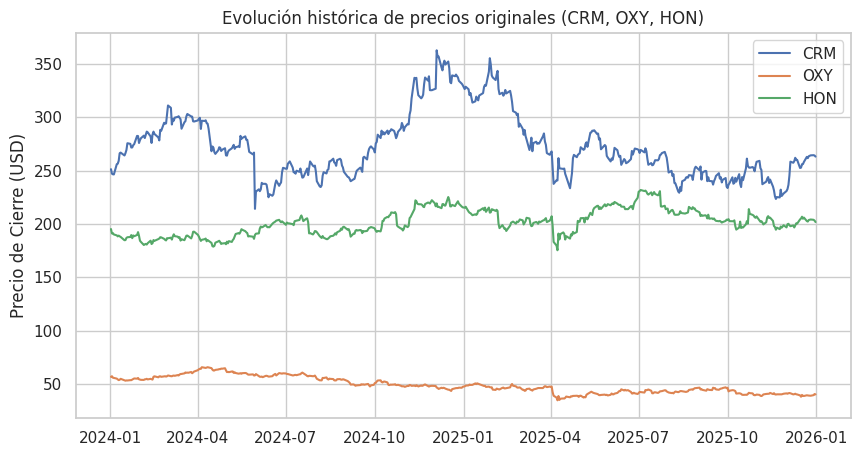

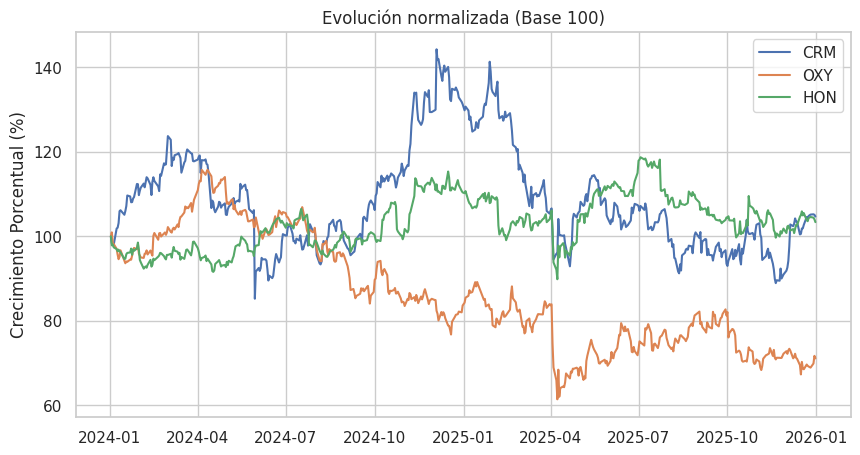

In [5]:
cierre = precios['Close']
plt.figure(figsize=(10, 5))
for activo in activos:
    plt.plot(cierre.index, cierre[activo], label=activo)
plt.title("Evolución histórica de precios originales (CRM, OXY, HON)")
plt.ylabel("Precio de Cierre (USD)")
plt.legend()
plt.show()
cierre_normalizado = cierre / cierre.iloc[0] * 100

plt.figure(figsize=(10, 5))
for activo in activos:
    plt.plot(cierre_normalizado.index, cierre_normalizado[activo], label=activo)
plt.title("Evolución normalizada (Base 100)")
plt.ylabel("Crecimiento Porcentual (%)")
plt.legend()
plt.show()

El activo más volátil es: CRM


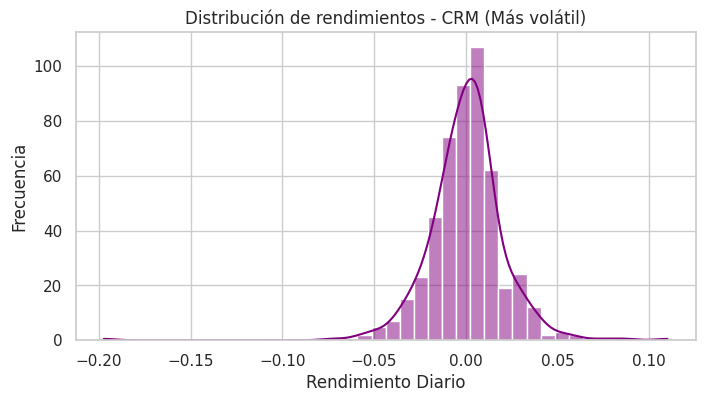

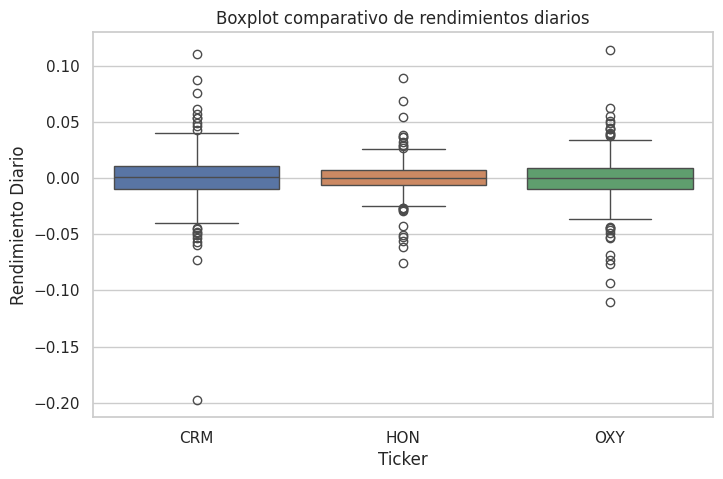

In [6]:
rendimientos = cierre.pct_change().dropna()
volatilidad = rendimientos.std()
activo_mas_volatil = volatilidad.idxmax()
print(f"El activo más volátil es: {activo_mas_volatil}")
plt.figure(figsize=(8, 4))
sns.histplot(rendimientos[activo_mas_volatil], bins=40, kde=True, color='purple')
plt.title(f"Distribución de rendimientos - {activo_mas_volatil} (Más volátil)")
plt.xlabel("Rendimiento Diario")
plt.ylabel("Frecuencia")
plt.show()
plt.figure(figsize=(8, 5))
sns.boxplot(data=rendimientos)
plt.title("Boxplot comparativo de rendimientos diarios")
plt.ylabel("Rendimiento Diario")
plt.show()

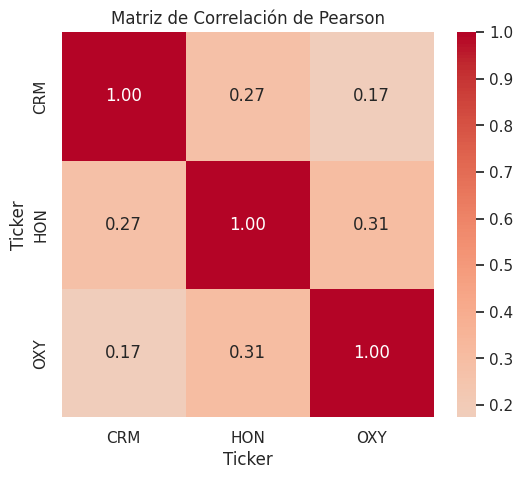

In [7]:
correlacion = rendimientos.corr()
plt.figure(figsize=(6, 5))
sns.heatmap(correlacion, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de Correlación de Pearson")
plt.show()

In [10]:
estadisticas = rendimientos.describe().T[['mean', '50%', 'std', 'min', 'max']]
estadisticas.columns = ['Media', 'Mediana', 'Desviación Estándar', 'Mínimo', 'Máximo']
print("--- Estadísticas Descriptivas ---")
print(estadisticas.round(4))

--- Estadísticas Descriptivas ---
         Media  Mediana  Desviación Estándar  Mínimo  Máximo
Ticker                                                      
CRM     0.0003   0.0013               0.0214 -0.1974  0.1099
HON     0.0002   0.0001               0.0136 -0.0759  0.0888
OXY    -0.0005  -0.0002               0.0189 -0.1101  0.1141


**CONCLUSION**


Al comparar ambos gráficos, es tecnicamente más correcto utilizar el gráfico normalizado en base 100 ya que elimina la distorsión visual causada por los diferentes precios absolutos (en dólares) de cada acción. El gráfico de precios reales no permite ver el rendimiento real si una acción cuesta 300 y otra de 50. por otro lado el gráfico normalizado iguala el punto de partida, lo que nos permite comparar de forma directa el crecimiento porcentual relativo y el rendimiento acumulado de CRM, OXY y HON, haciendo evidente cuál de los tres activos fue el más rentable durante el periodo analizado
